In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
fake_df = pd.read_csv("data/Fake.csv")
real_df = pd.read_csv("data/True.csv")

In [3]:
fake_df.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

In [4]:
real_df.isnull().sum()

title      0
text       0
subject    0
date       0
dtype: int64

In [5]:
fake_df.duplicated().sum()

np.int64(3)

In [6]:
real_df.duplicated().sum()

np.int64(206)

In [7]:
fake_df = fake_df.drop_duplicates()
real_df = real_df.drop_duplicates()

In [8]:
real_df.subject.unique()

<StringArray>
['politicsNews', 'worldnews']
Length: 2, dtype: str

In [9]:
fake_df.subject.unique()

<StringArray>
['News', 'politics', 'Government News', 'left-news', 'US_News', 'Middle-east']
Length: 6, dtype: str

In [10]:
fake_df.drop(['date', 'subject'], axis=1, inplace=True)
real_df.drop(['date', 'subject'], axis=1, inplace=True)

In [11]:
fake_df['class'] = 0
real_df['class'] = 1

Text(0, 0.5, 'Proportion of News Articles')

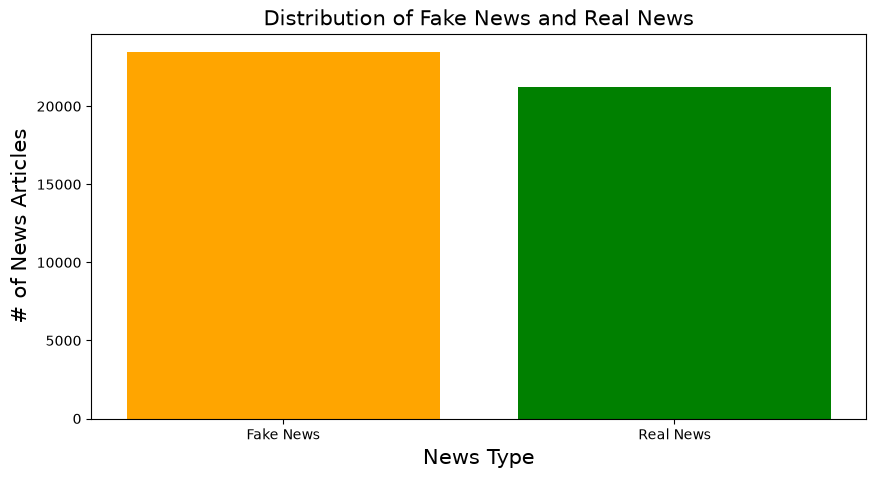

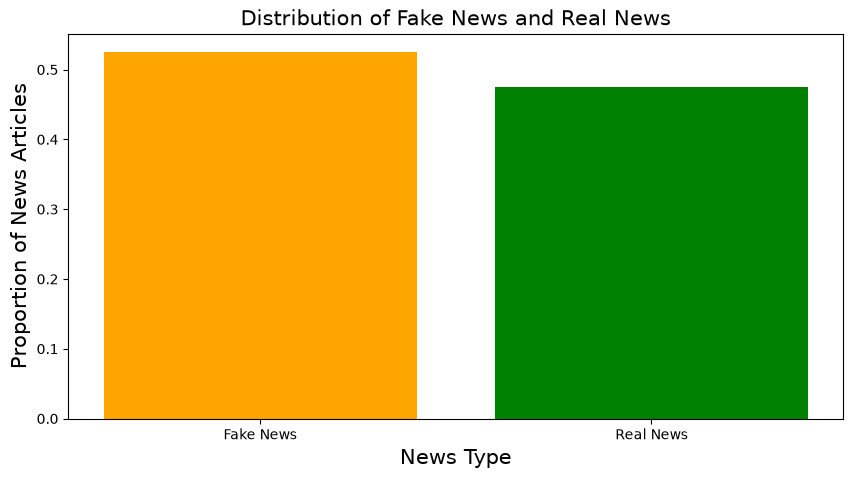

In [12]:
plt.figure(figsize=(10, 5))
plt.bar('Fake News', len(fake_df), color='orange')
plt.bar('Real News', len(real_df), color='green')
plt.title('Distribution of Fake News and Real News', size=15)
plt.xlabel('News Type', size=15)
plt.ylabel('# of News Articles', size=15)


total_len = len(fake_df) + len(real_df)
plt.figure(figsize=(10, 5))
plt.bar('Fake News', len(fake_df) / total_len, color='orange')
plt.bar('Real News', len(real_df) / total_len, color='green')
plt.title('Distribution of Fake News and Real News', size=15)
plt.xlabel('News Type', size=15)
plt.ylabel('Proportion of News Articles', size=15)

In [13]:
print('Difference in news articles:',len(fake_df)-len(real_df))

Difference in news articles: 2267


In [14]:
news_df = pd.concat([fake_df, real_df], ignore_index=True, sort=False)
news_df

,title,text,class
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,0
...,...,...,...
44684,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,1
44685,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",1
44686,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,1
44687,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,1


In [15]:
news_df['text'] = news_df['title'] + news_df['text']

In [16]:
news_df.drop('title', axis=1, inplace=True)

In [17]:
features = news_df['text']
targets = news_df['class']

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(features, targets, random_state=42, test_size=0.20)

In [19]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((35751,), (8938,), (35751,), (8938,))

In [20]:
import re

def normalize_data(data):
    normalized = []
    for i in data:
        i = i.lower()
        i = re.sub('https?://\S+|www\.\S+', '', i)
        # get rid of non words and extra spaces
        i = re.sub('\\W', ' ', i)
        i = re.sub('\n', '', i)
        i = re.sub(' +', ' ', i)
        i = re.sub('^ ', '', i)
        i = re.sub(' $', '', i)
        normalized.append(i)
    return normalized

X_train = normalize_data(X_train)
X_test = normalize_data(X_test)

<>:7: SyntaxWarning: invalid escape sequence '\S'
<>:7: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_4237/983489004.py:7: SyntaxWarning: invalid escape sequence '\S'
  i = re.sub('https?://\S+|www\.\S+', '', i)


In [21]:
from tensorflow.keras.preprocessing.text import Tokenizer
max_vocab = 10000
tokenizer = Tokenizer(num_words=max_vocab)
tokenizer.fit_on_texts(X_train)

I0000 00:00:1790669430.744475    4237 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790669430.745687    4237 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790669431.749120    4237 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790669437.009852    4237 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [22]:
X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

In [23]:
# maxlen_train = max([len(x) for x in X_train])
# maxlen_test = max([len(x) for x in X_test])

In [24]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
X_train = pad_sequences(X_train, padding='post', maxlen=256)
X_test = pad_sequences(X_test, padding='post', maxlen=256)

In [25]:
X_train

array([[   8,  121,    3, ..., 1430,  793,  924],
       [ 445, 1207,    2, ..., 7136,  584,  497],
       [4137, 3840, 1216, ...,    0,    0,    0],
       ...,
       [4758, 2195, 2232, ...,    6, 7531, 3479],
       [ 657,  237,    2, ...,  584,  497, 3411],
       [2029, 1707,    8, ...,  165,  318,   98]],
      shape=(35751, 256), dtype=int32)

In [26]:
from tensorflow.keras.layers import Embedding, Dense, SimpleRNN, LSTM, Bidirectional, Dropout, Input
from tensorflow.keras.models import Sequential

model = Sequential([
    Input(shape=(256,)),
    Embedding(max_vocab, 128),
    Bidirectional(LSTM(64,  return_sequences=True)),
    Bidirectional(LSTM(16)),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1)
])

model.summary()

E0000 00:00:1790669455.138242    4237 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 32)             │        18,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,399,553 (5.34 MB)

 Trainable params: 1,399,553 (5.34 MB)

 Non-trainable params: 0 (0.00 B)

model.compile, model.fit

In [27]:
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
model.compile(optimizer=Adam(1e-4), loss=BinaryCrossentropy(from_logits=True), metrics=["accuracy"])
model.fit(X_train, y_train, batch_size=30, epochs=10, validation_split=0.1, shuffle=True, callbacks=early_stop)

Epoch 1/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 304s 276ms/step - accuracy: 0.8659 - loss: 0.2626 - val_accuracy: 0.9228 - val_loss: 0.1813
Epoch 2/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 320s 298ms/step - accuracy: 0.9772 - loss: 0.0856 - val_accuracy: 0.9829 - val_loss: 0.0576
Epoch 3/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 363s 339ms/step - accuracy: 0.9916 - loss: 0.0354 - val_accuracy: 0.9869 - val_loss: 0.0423
Epoch 4/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 383s 339ms/step - accuracy: 0.9952 - loss: 0.0217 - val_accuracy: 0.9883 - val_loss: 0.0375
Epoch 5/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 298s 278ms/step - accuracy: 0.9968 - loss: 0.0154 - val_accuracy: 0.9891 - val_loss: 0.0410
Epoch 6/10
1073/1073 ━━━━━━━━━━━━━━━━━━━━ 336s 313ms/step - accuracy: 0.9979 - loss: 0.0109 - val_accuracy: 0.9894 - val_loss: 0.0436


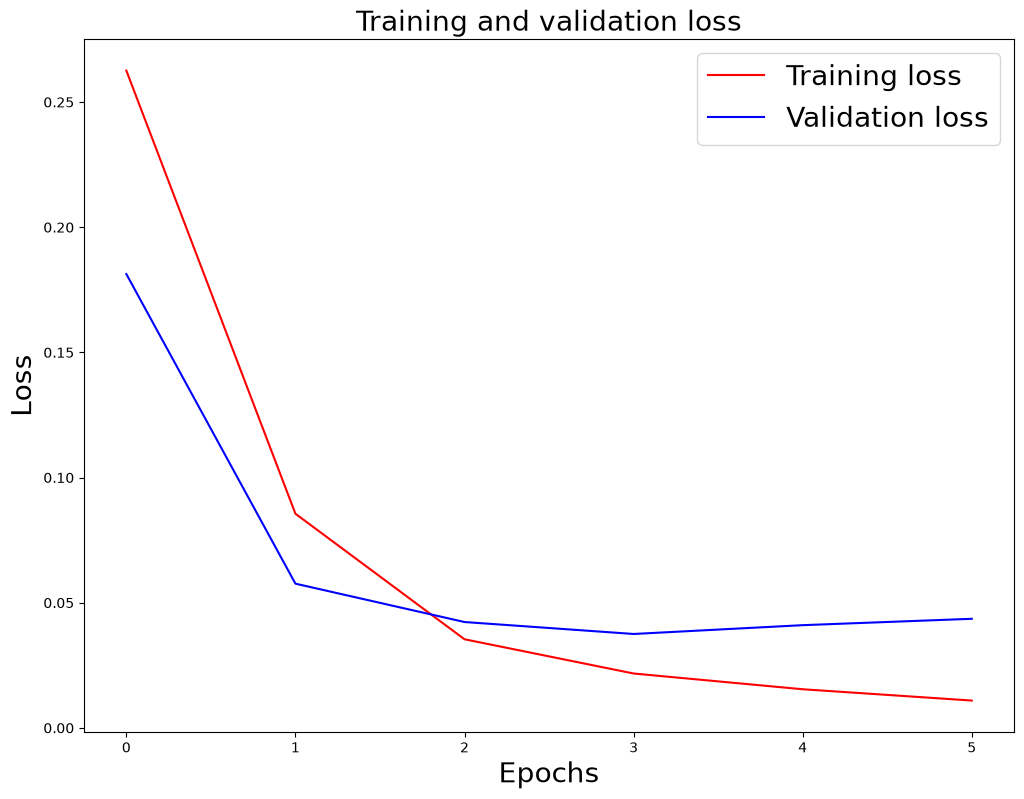

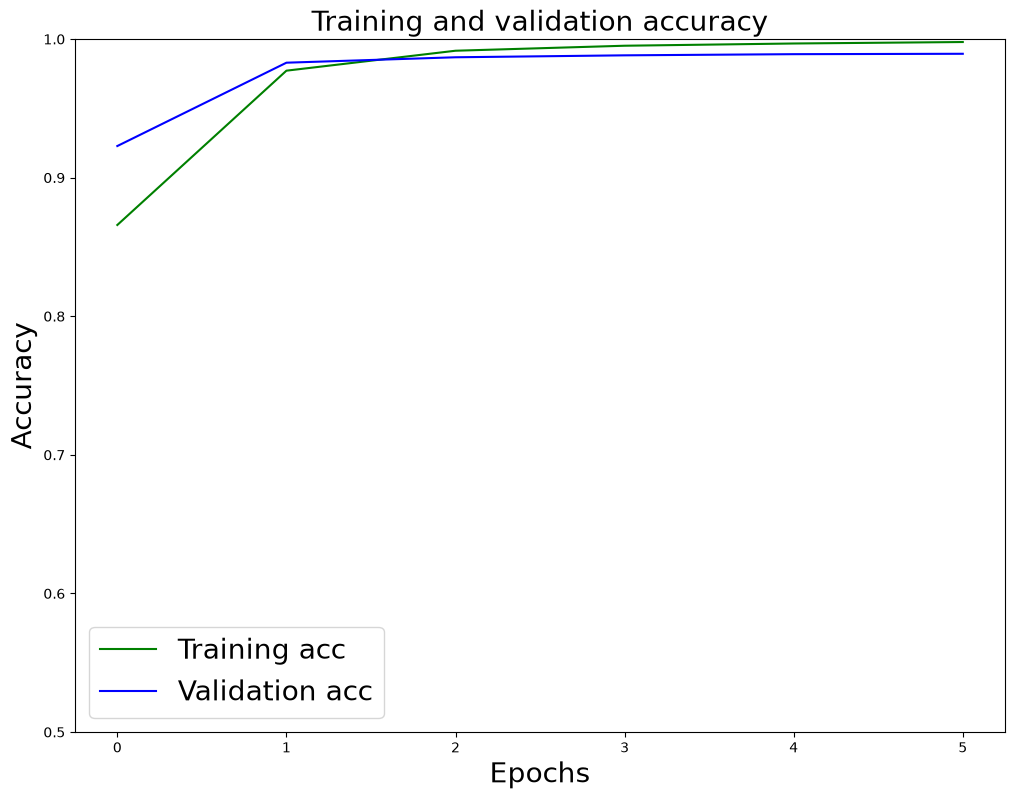

In [29]:
history = _

history_dict = history.history

acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']
loss = history_dict['loss']
val_loss = history_dict['val_loss']
epochs = history.epoch

plt.figure(figsize=(12,9))
plt.plot(epochs, loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss', size=20)
plt.xlabel('Epochs', size=20)
plt.ylabel('Loss', size=20)
plt.legend(prop={'size': 20})
plt.show()

plt.figure(figsize=(12,9))
plt.plot(epochs, acc, 'g', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy', size=20)
plt.xlabel('Epochs', size=20)
plt.ylabel('Accuracy', size=20)
plt.legend(prop={'size': 20})
plt.ylim((0.5,1))
plt.show()

In [30]:
model.evaluate(X_test, y_test)

280/280 ━━━━━━━━━━━━━━━━━━━━ 28s 98ms/step - accuracy: 0.9895 - loss: 0.0389


[0.03893238306045532, 0.989483118057251]

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

pred = model.predict(X_test)
binary_prediction = []
for i in pred: 
    if i >= 0.5:
        binary_prediction.append(1)
    else:
        binary_prediction.append(0)

print("Accuracy on testing set:", accuracy_score(binary_prediction, y_test))
print('Precision on testing set:', precision_score(binary_prediction, y_test))
print('Recall on testing set:', recall_score(binary_prediction, y_test))

280/280 ━━━━━━━━━━━━━━━━━━━━ 32s 109ms/step
Accuracy on testing set: 0.9894831058402327
Precision on testing set: 0.9842857142857143
Recall on testing set: 0.9932724651609803


[Text(0, 0.5, '0'), Text(0, 1.5, '1')]

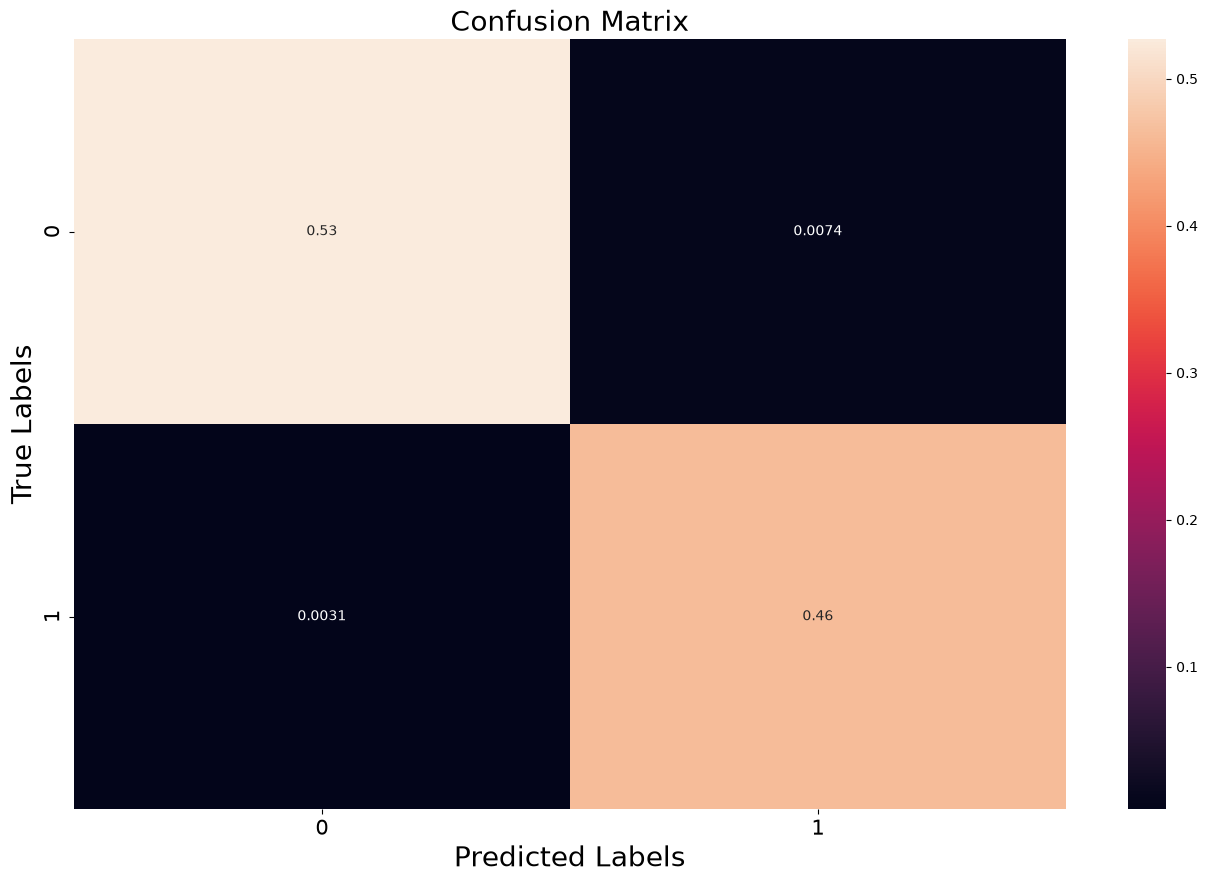

In [32]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(binary_prediction, y_test, normalize='all')
plt.figure(figsize=(16, 10))
ax= plt.subplot()
sns.heatmap(matrix, annot=True, ax = ax)

ax.set_xlabel('Predicted Labels', size=20)
ax.set_ylabel('True Labels', size=20)
ax.set_title('Confusion Matrix', size=20) 
ax.xaxis.set_ticklabels([0,1], size=15)
ax.yaxis.set_ticklabels([0,1], size=15)

In [33]:
e = model.layers[0]
weights = e.get_weights()[0]
print(weights.shape)

(10000, 128)


In [34]:
word_index = list(tokenizer.word_index.keys())
word_index = word_index[:max_vocab-1]

In [35]:
import io

out_v = io.open('fakenews_vecs.tsv', 'w', encoding='utf-8')
out_m = io.open('fakenews_meta.tsv', 'w', encoding='utf-8')

for num, word in enumerate(word_index):
  vec = weights[num+1] # skip 0, it's padding.
  out_m.write(word + "\n")
  out_v.write('\t'.join([str(x) for x in vec]) + "\n")
out_v.close()
out_m.close()